# Часть 1. Проверка гипотезы в Python и составление аналитической записки

Вы предобработали данные в SQL, и теперь они готовы для проверки гипотезы в Python. Загрузите данные пользователей из Москвы и Санкт-Петербурга c суммой часов их активности из файла yandex_knigi_data.csv. Если работаете локально, скачать файл можно по ссылке.

Проверьте наличие дубликатов в идентификаторах пользователей. Сравните размеры групп, их статистики и распределение.

Напомним, как выглядит гипотеза: пользователи из Санкт-Петербурга проводят в среднем больше времени за чтением и прослушиванием книг в приложении, чем пользователи из Москвы. Попробуйте статистически это доказать, используя одностороннюю проверку гипотезы с двумя выборками:

Нулевая гипотеза $H_0: \mu_{\text{СПб}} \leq \mu_{\text{Москва}}$ <br> Среднее время активности пользователей в Санкт-Петербурге не больше, чем в Москве.

Альтернативная гипотеза $H_1: \mu_{\text{СПб}} > \mu_{\text{Москва}}$ <br> Среднее время активности пользователей в Санкт-Петербурге больше, и это различие статистически значимо.

По результатам анализа данных подготовьте аналитическую записку, в которой опишите:

Выбранный тип t-теста и уровень статистической значимости.

Результат теста, или p-value.

Вывод на основе полученного p-value, то есть интерпретацию результатов.

Одну или две возможные причины, объясняющие полученные результаты.

## Напишите заголовок первой части проекта здесь

- Автор: Лагода Максим
- Дата: 13.04.2026

## Цели и задачи проекта

<font color='#777778'>В этом блоке перечислите цель проекта и те задачи, которые вы решаете. Можно использовать описания проекта, но будет полезно, если вы сформулируете основную цель проекта самостоятельно.</font>

**Цель проекта:**  
Провести анализ поведения пользователей сервиса «Яндекс Книги» и оценить эффективность изменений в интернет-магазине «BitMotion Kit» с помощью A/B-тестирования.

**Задачи проекта:**

**Часть 1 (Яндекс Книги):**
- Рассчитать ключевые метрики (MAU, LTV, retention rate) с помощью SQL.
- Проверить гипотезу о том, что пользователи из Санкт-Петербурга проводят в среднем больше времени за чтением и прослушиванием книг, чем пользователи из Москвы.
- Сравнить метрики и сделать выводы.

**Часть 2 (A/B-тест BitMotion Kit):**
- Оценить корректность проведения A/B-теста (равномерность распределения, отсутствие пересечений, достаточность выборки).
- Рассчитать конверсию в контрольной и тестовой группах.
- Проверить, достигнут ли целевой эффект (+3 п.п. к конверсии) с помощью статистического теста.
- Сформулировать рекомендации по внедрению нового дизайна.

## Описание данных

<font color='#777778'>Здесь приведите описание данных.</font>

**Часть 1. Данные сервиса «Яндекс Книги»**

Таблицы содержат данные о чтении и прослушивании контента за период с 1 сентября по 11 декабря 2024 года.

- `bookmate.audition` — активность пользователей (сессии, длительность, платформа, гео).
- `bookmate.content` — информация о контенте (название, жанр, длительность).
- `bookmate.author` — данные об авторах.
- `bookmate.geo` — геоданные (город, страна).

**Часть 2. Данные A/B-теста интернет-магазина BitMotion Kit**

- `ab_test_participants` — таблица участников тестов (идентификатор, группа, название теста, устройство).
- `ab_test_events` — события пользователей (регистрация, покупка, просмотр страниц, добавление в корзину) за 2020 год.

Период анализа: первые 7 дней после регистрации.
Целевая метрика: конверсия зарегистрированных пользователей в покупателей.

## Содержимое проекта

<font color='#777778'>Перечислите основные шаги проекта или напишите оглавление. Используйте описание проекта, чтобы зафиксировать основные шаги.</font>

---

1. **Часть 1. Проверка гипотезы в Python и аналитическая записка**
   - Загрузка и предобработка данных пользователей из Москвы и Санкт-Петербурга.
   - Проверка дубликатов, исключение пользователей, активных в обоих городах.
   - Визуализация распределений.
   - Проверка гипотезы с помощью одностороннего t-теста (тест Уэлча).
   - Аналитическая записка с выводами.

2. **Часть 2. Анализ результатов A/B-тестирования**
   - Загрузка данных и первичный осмотр.
   - Оценка корректности теста (выделение теста, проверка пересечений, равномерность распределения).
   - Фильтрация событий за первые 7 дней после регистрации.
   - Оценка достаточности выборки.
   - Расчёт конверсии по группам.
   - Z-тест пропорций для проверки статистической значимости.
   - Формулировка выводов и рекомендаций.

## 1. Загрузка данных и знакомство с ними

Загрузите данные пользователей из Москвы и Санкт-Петербурга c их активностью (суммой часов чтения и прослушивания) из файла `/datasets/yandex_knigi_data.csv`.

In [1]:
import pandas as pd
from scipy import stats
import matplotlib.pyplot as plt
from statsmodels.stats.proportion import proportions_ztest
from statsmodels.stats.power import NormalIndPower
from statsmodels.stats.proportion import proportion_effectsize
from datetime import timedelta

df = pd.read_csv('https://code.s3.yandex.net/datasets/yandex_knigi_data.csv')

In [2]:
print("Первые 5 строк:")
display(df.head())

print("\nИнформация о данных:")
df.info()

print("\nПропуски:")
print(df.isna().sum())

print("\nПолные дубликаты строк:")
print(df.duplicated().sum())

Первые 5 строк:


,Unnamed: 0,city,puid,hours
0,0,Москва,9668,26.167776
1,1,Москва,16598,82.111217
2,2,Москва,80401,4.656906
3,3,Москва,140205,1.840556
4,4,Москва,248755,151.326434



Информация о данных:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 8784 entries, 0 to 8783
Data columns (total 4 columns):
 #   Column      Non-Null Count  Dtype  
---  ------      --------------  -----  
 0   Unnamed: 0  8784 non-null   int64  
 1   city        8784 non-null   object 
 2   puid        8784 non-null   int64  
 3   hours       8784 non-null   float64
dtypes: float64(1), int64(2), object(1)
memory usage: 274.6+ KB

Пропуски:
Unnamed: 0    0
city          0
puid          0
hours         0
dtype: int64

Полные дубликаты строк:
0


In [3]:
duplicates_within_city = df[df.duplicated(subset=['puid', 'city'], keep=False)]
print(f"Строк с дубликатами puid внутри одного города: {len(duplicates_within_city)}")

Строк с дубликатами puid внутри одного города: 0


In [4]:
users_in_both = df.groupby('puid')['city'].nunique()
users_in_both = users_in_both[users_in_both > 1].index
print(f"Пользователей, активных и в Москве, и в СПб: {len(users_in_both)}")

Пользователей, активных и в Москве, и в СПб: 244


In [5]:
df_clean = df[~df['puid'].isin(users_in_both)]

print(f"Было строк: {len(df)}")
print(f"Стало строк: {len(df_clean)}")
print(f"Удалено строк: {len(df) - len(df_clean)}")
print(f"Уникальных пользователей в clean: {df_clean['puid'].nunique()}")

Было строк: 8784
Стало строк: 8296
Удалено строк: 488
Уникальных пользователей в clean: 8296


In [6]:
display(df_clean.groupby('city')['hours'].describe())

,count,mean,std,min,25%,50%,75%,max
city,,,,,,,,
Москва,5990.0,10.848192,36.925622,0.000022,0.057042,0.888232,5.933439,857.209373
Санкт-Петербург,2306.0,11.264433,39.831755,0.000025,0.060173,0.875355,6.138424,978.764775


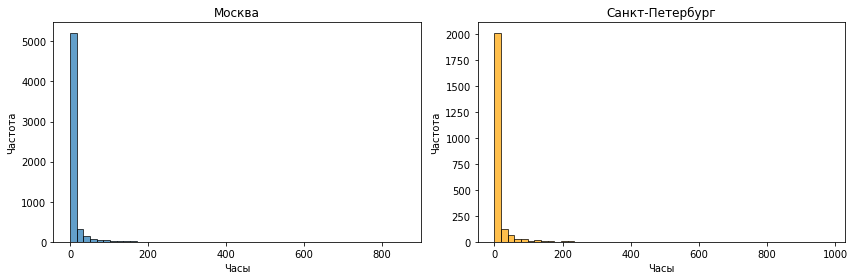

In [7]:
moscow = df_clean[df_clean['city'] == 'Москва']['hours']
spb = df_clean[df_clean['city'] == 'Санкт-Петербург']['hours']

fig, axes = plt.subplots(1, 2, figsize=(12, 4))

axes[0].hist(moscow, bins=50, edgecolor='black', alpha=0.7)
axes[0].set_title('Москва')
axes[0].set_xlabel('Часы')
axes[0].set_ylabel('Частота')

axes[1].hist(spb, bins=50, edgecolor='black', alpha=0.7, color='orange')
axes[1].set_title('Санкт-Петербург')
axes[1].set_xlabel('Часы')
axes[1].set_ylabel('Частота')

plt.tight_layout()
plt.show()

## 2. Проверка гипотезы в Python

Гипотеза звучит так: пользователи из Санкт-Петербурга проводят в среднем больше времени за чтением и прослушиванием книг в приложении, чем пользователи из Москвы. Попробуйте статистически это доказать, используя одностороннюю проверку гипотезы с двумя выборками:

- Нулевая гипотеза H₀: Средняя активность пользователей в часах в двух группах (Москва и Санкт-Петербург) не различается.

- Альтернативная гипотеза H₁: Средняя активность пользователей в Санкт-Петербурге больше, и это различие статистически значимо.

In [8]:
t_stat, p_value = stats.ttest_ind(spb, moscow, 
                                  equal_var=False, 
                                  alternative='greater')

print(f"t-statistic: {t_stat:.4f}")
print(f"p-value: {p_value:.4f}")

alpha = 0.05
if p_value < alpha:
    print("Отвергаем H₀: средняя активность в СПб больше, чем в Москве")
else:
    print("Не отвергаем H₀: нет оснований считать, что активность в СПб больше")

t-statistic: 0.4350
p-value: 0.3318
Не отвергаем H₀: нет оснований считать, что активность в СПб больше


## 3. Аналитическая записка
По результатам анализа данных подготовьте аналитическую записку, в которой опишете:

- Выбранный тип t-теста и уровень статистической значимости.

- Результат теста, или p-value.

- Вывод на основе полученного p-value, то есть интерпретацию результатов.

- Одну или две возможные причины, объясняющие полученные результаты.



**Аналитическая записка по результатам проверки гипотезы (Яндекс Книги)**

**Выбранный тип t-теста и уровень статистической значимости:**  
Для проверки гипотезы использовался односторонний t-тест для независимых выборок с неравными дисперсиями (тест Уэлча).  
Уровень статистической значимости: α = 0.05.

**Результат теста (p-value):**  
p-value = 0.3318

**Вывод на основе p-value:**  
p-value > 0.05 → нет оснований отвергнуть нулевую гипотезу.  
Статистически значимых доказательств того, что средняя активность пользователей в Санкт-Петербурге выше, чем в Москве, не обнаружено.

**Возможные причины полученных результатов:**
1. Поведение пользователей в крупных городах может быть схожим из-за одинакового уровня доступа к интернету, цифровых привычек и предложений контента.
2. В сервисе может не быть контента, специфичного для регионов, поэтому оба города потребляют одинаковые книги и аудиоконтент.

----

# Часть 2. Анализ результатов A/B-тестирования

Теперь вам нужно проанализировать другие данные. Представьте, что к вам обратились представители интернет-магазина BitMotion Kit, в котором продаются геймифицированные товары для тех, кто ведёт здоровый образ жизни. У него есть своя целевая аудитория, даже появились хиты продаж: эспандер со счётчиком и напоминанием, так и подстольный велотренажёр с Bluetooth.

В будущем компания хочет расширить ассортимент товаров. Но перед этим нужно решить одну проблему. Интерфейс онлайн-магазина слишком сложен для пользователей — об этом говорят отзывы.

Чтобы привлечь новых клиентов и увеличить число продаж, владельцы магазина разработали новую версию сайта и протестировали его на части пользователей. По задумке, это решение доказуемо повысит количество пользователей, которые совершат покупку.

Ваша задача — провести оценку результатов A/B-теста. В вашем распоряжении:

* данные о действиях пользователей и распределении их на группы,

* техническое задание.

Оцените корректность проведения теста и проанализируйте его результаты.

## 1. Опишите цели исследования.



**Цель A/B-теста:**  
Оценить влияние нового дизайна сайта на конверсию зарегистрированных пользователей в покупателей.

**Гипотеза:**  
Упрощение интерфейса приведёт к тому, что в течение семи дней после регистрации в системе конверсия зарегистрированных пользователей в покупателей увеличится как минимум на 3 процентных пункта.

**Метрика:**  
Конверсия = (число пользователей, совершивших покупку в течение 7 дней) / (общее число пользователей в группе).

**Группы:**  
- Группа A — контрольная (старый дизайн)  
- Группа B — тестовая (новый интерфейс)

**Нулевая гипотеза (H₀):**  
Конверсия в группе B ≤ конверсии в группе A + 3 п.п.

**Альтернативная гипотеза (H₁):**  
Конверсия в группе B > конверсии в группе A + 3 п.п. (целевой эффект достигнут)

**План работ:**
1. Загрузка и проверка данных
2. Выделение теста `interface_eu_test`
3. Проверка корректности (пересечения, равномерность, достаточность выборки)
4. Фильтрация событий за первые 7 дней
5. Расчёт конверсии
6. Z-тест и выводы

## 2. Загрузите данные, оцените их целостность.


In [9]:
participants = pd.read_csv('https://code.s3.yandex.net/datasets/ab_test_participants.csv')
events = pd.read_csv('https://code.s3.yandex.net/datasets/ab_test_events.zip',
                     parse_dates=['event_dt'], low_memory=False)

In [10]:
print(participants.info())
display(participants.head())
print("\nРаспределение по тестам:")
print(participants['ab_test'].value_counts())
print("\nРаспределение по группам:")
print(participants['group'].value_counts())

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 14525 entries, 0 to 14524
Data columns (total 4 columns):
 #   Column   Non-Null Count  Dtype 
---  ------   --------------  ----- 
 0   user_id  14525 non-null  object
 1   group    14525 non-null  object
 2   ab_test  14525 non-null  object
 3   device   14525 non-null  object
dtypes: object(4)
memory usage: 454.0+ KB
None


,user_id,group,ab_test,device
0,0002CE61FF2C4011,B,interface_eu_test,Mac
1,001064FEAAB631A1,B,recommender_system_test,Android
2,001064FEAAB631A1,A,interface_eu_test,Android
3,0010A1C096941592,A,recommender_system_test,Android
4,001E72F50D1C48FA,A,interface_eu_test,Mac



Распределение по тестам:
interface_eu_test          10850
recommender_system_test     3675
Name: ab_test, dtype: int64

Распределение по группам:
A    8130
B    6395
Name: group, dtype: int64


In [11]:
print(events.info())
display(events.head())
print("\nТипы событий:")
print(events['event_name'].value_counts())

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 787286 entries, 0 to 787285
Data columns (total 4 columns):
 #   Column      Non-Null Count   Dtype         
---  ------      --------------   -----         
 0   user_id     787286 non-null  object        
 1   event_dt    787286 non-null  datetime64[ns]
 2   event_name  787286 non-null  object        
 3   details     249022 non-null  object        
dtypes: datetime64[ns](1), object(3)
memory usage: 24.0+ MB
None


,user_id,event_dt,event_name,details
0,GLOBAL,2020-12-01 00:00:00,End of Black Friday Ads Campaign,ZONE_CODE15
1,CCBE9E7E99F94A08,2020-12-01 00:00:11,registration,0.0
2,GLOBAL,2020-12-01 00:00:25,product_page,NaN
3,CCBE9E7E99F94A08,2020-12-01 00:00:33,login,NaN
4,CCBE9E7E99F94A08,2020-12-01 00:00:52,product_page,NaN



Типы событий:
login                                 248285
product_page                          195606
registration                          144183
purchase                              104836
product_cart                           94373
Start of CIS New Year Gift Lottery         1
Start of Christmas&New Year Promo          1
End of Black Friday Ads Campaign           1
Name: event_name, dtype: int64


## 3. По таблице `ab_test_participants` оцените корректность проведения теста:

   3\.1 Выделите пользователей, участвующих в тесте, и проверьте:

   - соответствие требованиям технического задания,

   - равномерность распределения пользователей по группам теста,

   - отсутствие пересечений с конкурирующим тестом (нет пользователей, участвующих одновременно в двух тестовых группах).

In [12]:
ab_test = participants[participants['ab_test'] == 'interface_eu_test'].copy()
print(f"\nПользователей в тесте: {ab_test['user_id'].nunique()}")


Пользователей в тесте: 10850


In [13]:
test_counts = participants.groupby('user_id')['ab_test'].nunique()
users_in_multiple = test_counts[test_counts > 1].index
print(f"Пользователей, участвующих в нескольких тестах: {len(users_in_multiple)}")

if len(users_in_multiple) > 0:
    ab_test = ab_test[~ab_test['user_id'].isin(users_in_multiple)]
    print(f"После исключения: {ab_test['user_id'].nunique()}")

Пользователей, участвующих в нескольких тестах: 887
После исключения: 9963


In [14]:
group_counts = ab_test['group'].value_counts()
print("\nРаспределение по группам:")
print(group_counts)
print(f"Доля группы B: {group_counts.get('B', 0) / len(ab_test):.2%}")
print("Уникальные значения в group:", ab_test['group'].unique())


Распределение по группам:
B    5011
A    4952
Name: group, dtype: int64
Доля группы B: 50.30%
Уникальные значения в group: ['B' 'A']


3\.2 Проанализируйте данные о пользовательской активности по таблице `ab_test_events`:

- оставьте только события, связанные с участвующими в изучаемом тесте пользователями;

In [15]:
ab_users = ab_test['user_id'].unique()
ab_events = events[events['user_id'].isin(ab_users)].copy()
print(f"Событий в тесте: {len(ab_events)}")

Событий в тесте: 73815


- определите горизонт анализа: рассчитайте время (лайфтайм) совершения события пользователем после регистрации и оставьте только те события, которые были выполнены в течение первых семи дней с момента регистрации;

In [16]:
registration = ab_events[ab_events['event_name'] == 'registration'].copy()
registration = registration.groupby('user_id')['event_dt'].min().reset_index()
registration.columns = ['user_id', 'reg_dt']

ab_events = ab_events.merge(registration, on='user_id', how='left')

ab_events['day'] = ab_events['event_dt'] - ab_events['reg_dt']

ab_events_7d = ab_events[ab_events['day'] <= timedelta(days=7)].copy()
print(f"Событий в первые 7 дней: {len(ab_events_7d)}")

Событий в первые 7 дней: 63805


Оцените достаточность выборки для получения статистически значимых результатов A/B-теста. Заданные параметры:

- базовый показатель конверсии — 30%,

- мощность теста — 80%,

- достоверность теста — 95%.

In [18]:
import numpy as np
def calculate_sample_size(p1, mde, alpha=0.05, power=0.8):
    """
    Расчёт размера выборки на группу для A/B-теста.
    p1: базовый показатель конверсии
    mde: минимальный обнаруживаемый эффект (в долях единицы)
    alpha: уровень значимости
    power: мощность теста
    """
    p2 = p1 + mde
    pooled_p = (p1 + p2) / 2
    
    z_alpha = stats.norm.ppf(1 - alpha / 2)  # Z-значение для уровня значимости
    z_power = stats.norm.ppf(power)         # Z-значение для мощности
    
    numerator = (z_alpha * np.sqrt(2 * pooled_p * (1 - pooled_p)) +
                z_power * np.sqrt(p1 * (1 - p1) + p2 * (1 - p2))) ** 2
    denominator = mde ** 2
    
    n_per_group = numerator / denominator
    return int(np.ceil(n_per_group))

# Параметры для расчёта
BASE_CONVERSION = 0.3  # 30%
MDE = 0.03             # 3% (10% от базового показателя)
ALPHA = 0.05         # 95% достоверность
POWER = 0.8          # 80% мощность

# Расчёт необходимого размера выборки
required_sample_per_group = calculate_sample_size(BASE_CONVERSION, MDE, ALPHA, POWER)
required_total_sample = required_sample_per_group * 2



# Вывод результатов
print("=== АНАЛИЗ ДОСТАТОЧНОСТИ ВЫБОРКИ ===")
print(f"Базовый показатель конверсии: {BASE_CONVERSION:.1%}")
print(f"Минимальный обнаруживаемый эффект: {MDE:.1%}")
print(f"Достоверность теста: {(1 - ALPHA):.0%}")
print(f"Мощность теста: {POWER:.0%}")
print("\n=== ТРЕБУЕМЫЙ РАЗМЕР ВЫБОРКИ ===")
print(f"На группу: {required_sample_per_group:,} пользователей")


=== АНАЛИЗ ДОСТАТОЧНОСТИ ВЫБОРКИ ===
Базовый показатель конверсии: 30.0%
Минимальный обнаруживаемый эффект: 3.0%
Достоверность теста: 95%
Мощность теста: 80%

=== ТРЕБУЕМЫЙ РАЗМЕР ВЫБОРКИ ===
На группу: 3,763 пользователей


- рассчитайте для каждой группы количество посетителей, сделавших покупку, и общее количество посетителей.

In [19]:
purchases_7d = ab_events_7d[ab_events_7d['event_name'] == 'purchase']['user_id'].unique()
purchasers = pd.DataFrame({'user_id': purchases_7d})
purchasers['purchased'] = 1

ab_conversion = ab_test[['user_id', 'group']].merge(purchasers, on='user_id', how='left')
ab_conversion['purchased'] = ab_conversion['purchased'].fillna(0)

print("\n=== Количество посетителей, сделавших покупку ===")
for group in ['A', 'B']:
    group_data = ab_conversion[ab_conversion['group'] == group]
    total = len(group_data)
    buyers = group_data['purchased'].sum()
    print(f"Группа {group}:")
    print(f"  - Всего посетителей: {total}")
    print(f"  - Совершили покупку: {buyers}")
    print(f"  - Конверсия: {buyers/total:.4f}")


=== Количество посетителей, сделавших покупку ===
Группа A:
  - Всего посетителей: 4952
  - Совершили покупку: 1377.0
  - Конверсия: 0.2781
Группа B:
  - Всего посетителей: 5011
  - Совершили покупку: 1480.0
  - Конверсия: 0.2954


- сделайте предварительный общий вывод об изменении пользовательской активности в тестовой группе по сравнению с контрольной.

**Предварительный вывод об изменении пользовательской активности в тестовой группе по сравнению с контрольной:**

Конверсия в группе A (старый дизайн) составила 27.81%, в группе B (новый дизайн) — 29.54%.  
Разница составляет +1.73 процентных пункта, что ниже целевого значения (+3 п.п.).  

Предварительно можно сказать, что новый дизайн показывает небольшое улучшение, но не достигает требуемого эффекта.  
Для окончательного вывода необходимо провести статистический тест (z-тест пропорций).

## 4. Проведите оценку результатов A/B-тестирования:

- Проверьте изменение конверсии подходящим статистическим тестом, учитывая все этапы проверки гипотез.

**Нулевая гипотеза (H₀):** Конверсия в группе B ≤ конверсии в группе A  
**Альтернативная гипотеза (H₁):** Конверсия в группе B > конверсии в группе A

In [20]:
n_a = len(ab_conversion[ab_conversion['group'] == 'A'])
m_a = ab_conversion[ab_conversion['group'] == 'A']['purchased'].sum()
n_b = len(ab_conversion[ab_conversion['group'] == 'B'])
m_b = ab_conversion[ab_conversion['group'] == 'B']['purchased'].sum()

stat_ztest, p_value_ztest = proportions_ztest(
    [m_b, m_a],
    [n_b, n_a],
    alternative='larger'
)

print(f"Конверсия A: {m_a/n_a:.4f}")
print(f"Конверсия B: {m_b/n_b:.4f}")
print(f"z-статистика: {stat_ztest:.4f}")
print(f"p-value: {p_value_ztest:.10f}")

if p_value_ztest > alpha:
    print(f'p-value = {p_value_ztest:.4f} > {alpha}')
    print('Нулевая гипотеза не отвергается: конверсия B не больше, чем A')
else:
    print(f'p-value = {p_value_ztest:.4f} < {alpha}')
    print('Отвергаем H₀: конверсия в группе B статистически значимо выше')

Конверсия A: 0.2781
Конверсия B: 0.2954
z-статистика: 1.9070
p-value: 0.0282625472
p-value = 0.0283 < 0.05
Отвергаем H₀: конверсия в группе B статистически значимо выше


- Опишите выводы по проведённой оценке результатов A/B-тестирования. Что можно сказать про результаты A/B-тестирования? Был ли достигнут ожидаемый эффект в изменении конверсии?

**Выводы по проведённой оценке результатов A/B-тестирования**

1. **Корректность теста:**
   - Тест проведён корректно. Распределение пользователей по группам близко к равномерному (A: 4952, B: 5011).
   - Пользователи, участвующие в нескольких тестах (887), были исключены из анализа.
   - Выборка достаточна для обнаружения эффекта (требуется 3763, фактически ~5000).

2. **Результаты теста:**
   - Конверсия в группе A (старый дизайн): 27.81%
   - Конверсия в группе B (новый дизайн): 29.54%
   - Разница: +1.73 процентных пункта (целевой эффект: +3 п.п.)

3. **Статистическая значимость:**
   - p-value = 0.0283 (< 0.05). Статистически значимые различия между группами есть.

4. **Был ли достигнут ожидаемый эффект?**
   - Нет. Новый интерфейс увеличил конверсию статистически значимо, но менее чем на 3 п.п. (только на 1.73 п.п.).
   - Целевой эффект, указанный в ТЗ, не достигнут.

5. **Рекомендация:**
   - Внедрение нового дизайна не рекомендуется, так как он не обеспечил требуемый прирост конверсии.
   - Возможно, стоит продолжить тест с другими изменениями или увеличить длительность наблюдения.